# Automotive RF feature-engineering experiment

Exploratory evidence only. This notebook does not replace Automotive v1, export artifacts, or evaluate the sealed test partition.


In [1]:
from pathlib import Path
from time import perf_counter
import joblib
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    plt = None
    print('Charts are skipped in this minimal ML runtime because Matplotlib is not installed.')
import numpy as np
import pandas as pd
import shap
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

def display(value):
    print(value.to_string() if hasattr(value, 'to_string') else value)

RANDOM_SEED = 42
FEATURES = ['Opportunity Amount USD', 'Revenue From Client Past Two Years', 'Route To Market', 'Supplies Group', 'Supplies Subgroup']
AMOUNT = FEATURES[0]
SUBGROUPS = ['Batteries & Accessories', 'Exterior Accessories', 'Garage & Car Care', 'Interior Accessories', 'Replacement Parts', 'Towing & Hitches', 'Car Electronics', 'Tires & Wheels', 'Motorcycle Parts', 'Shelters & RV']
root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
raw = pd.read_csv(root / 'datasets' / 'IBM-sales-opportunity.csv', keep_default_na=False, na_values=[''])
cleaned = raw.drop_duplicates()
cleaned = cleaned.loc[~cleaned['Opportunity Number'].duplicated(keep=False)].copy()
cleaned['target'] = cleaned['Opportunity Result'].map({'Won': 1, 'Loss': 0})
assert cleaned['target'].notna().all() and cleaned['Opportunity Number'].is_unique
development, full_test = train_test_split(cleaned, test_size=0.20, stratify=cleaned.target, random_state=RANDOM_SEED)
full_fit, full_validation = train_test_split(development, test_size=0.25, stratify=development.target, random_state=RANDOM_SEED + 1)
full_train, full_calibration = train_test_split(full_fit, test_size=1/6, stratify=full_fit.target, random_state=RANDOM_SEED + 2)
partitions = {name: frame.loc[frame['Supplies Subgroup'].isin(SUBGROUPS)].copy() for name, frame in {'Training': full_train, 'Calibration': full_calibration, 'Validation': full_validation, 'Test': full_test}.items()}
assert sum(map(len, partitions.values())) == 75158
summary = pd.DataFrame([{'partition': name, 'opportunities': len(frame), 'Won': int(frame.target.sum()), 'Loss': int((frame.target == 0).sum())} for name, frame in partitions.items()])
display(summary)
print('Test membership is created but sealed; no test rows are scored in this notebook.')


Charts are skipped in this minimal ML runtime because Matplotlib is not installed.
     partition  opportunities   Won   Loss
0     Training          37586  8564  29022
1  Calibration           7517  1706   5811
2   Validation          15025  3410  11615
3         Test          15030  3423  11607
Test membership is created but sealed; no test rows are scored in this notebook.


In [2]:
def make_preprocessor(columns):
    categorical = [column for column in columns if column != AMOUNT]
    return ColumnTransformer([
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical),
        ('amount', Pipeline([('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')), ('scale', StandardScaler())]), [AMOUNT]),
    ])

def metrics(actual, probabilities):
    return {'ROC-AUC': roc_auc_score(actual, probabilities), 'Average Precision': average_precision_score(actual, probabilities), 'Brier Score': brier_score_loss(actual, probabilities)}

train, validation = partitions['Training'], partitions['Validation']
frozen_parameters = {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 30, 'max_features': 0.8, 'n_jobs': 2, 'random_state': 42}
previous_80_tree_parameters = {'n_estimators': 80, 'max_depth': 8, 'min_samples_leaf': 60, 'max_features': 0.5, 'n_jobs': 2, 'random_state': 42}
parameter_audit = pd.DataFrame({'Frozen v1': frozen_parameters, 'Previous 80-tree trial': previous_80_tree_parameters})
parameter_audit['same'] = parameter_audit['Frozen v1'] == parameter_audit['Previous 80-tree trial']
display(parameter_audit)
print('Audit: preprocessing, training membership and seed matched; depth, leaf size and max_features did not. The ROC-AUC decline cannot be attributed to tree count alone.')

baseline = joblib.load(root / 'models' / 'automotive_v1' / 'automotive_5_primary.joblib')
assert baseline.named_steps['model'].get_params()['n_estimators'] == 200
baseline_probabilities = baseline.predict_proba(validation[FEATURES])[:, 1]
baseline_metrics = metrics(validation.target, baseline_probabilities)
frozen_metrics = {'ROC-AUC': 0.82083, 'Average Precision': 0.60763, 'Brier Score': 0.12921}
assert all(np.isclose(baseline_metrics[key], frozen_metrics[key], atol=1e-5) for key in frozen_metrics)
display(pd.DataFrame([{'model': 'Frozen Automotive v1 artifact', **baseline_metrics}]).round(5))


                  Frozen v1  Previous 80-tree trial   same
n_estimators          200.0                    80.0  False
max_depth              12.0                     8.0  False
min_samples_leaf       30.0                    60.0  False
max_features            0.8                     0.5  False
n_jobs                  2.0                     2.0   True
random_state           42.0                    42.0   True
Audit: preprocessing, training membership and seed matched; depth, leaf size and max_features did not. The ROC-AUC decline cannot be attributed to tree count alone.
                           model  ROC-AUC  Average Precision  Brier Score
0  Frozen Automotive v1 artifact  0.82083            0.60763      0.12921


In [3]:
def outcome_summary(columns):
    table = train.groupby(columns, observed=True).target.agg(opportunities='size', Won='sum', win_rate='mean')
    return table.assign(Loss=lambda frame: frame.opportunities - frame.Won)

for label, columns in [('Supplies Group', ['Supplies Group']), ('Supplies Subgroup', ['Supplies Subgroup']), ('Route To Market', ['Route To Market'])]:
    print(f'\n{label}')
    display(outcome_summary(columns).sort_values('opportunities', ascending=False).round(4))

interaction_support = outcome_summary(['Supplies Subgroup', 'Route To Market']).sort_values('opportunities', ascending=False)
display(interaction_support.round(4))
print(f'Interaction cells: {len(interaction_support)}; minimum={interaction_support.opportunities.min()}; median={interaction_support.opportunities.median():.0f}; cells with >=100 records={(interaction_support.opportunities >= 100).sum()}.')
print('Subgroup determines group:', train.groupby('Supplies Subgroup')['Supplies Group'].nunique().eq(1).all())
print('Evidence: 30 of 49 interaction cells have at least 100 training records; sparse cells remain protected by min_samples_leaf=30 and should not be overinterpreted.')



Supplies Group
                        opportunities   Won  win_rate   Loss
Supplies Group                                              
Car Accessories                 24762  5733    0.2315  19029
Performance & Non-auto          12381  2754    0.2224   9627
Tires & Wheels                    307    47    0.1531    260
Car Electronics                   136    30    0.2206    106

Supplies Subgroup
                         opportunities   Won  win_rate  Loss
Supplies Subgroup                                           
Motorcycle Parts                  7594  1869    0.2461  5725
Exterior Accessories              6903  1713    0.2482  5190
Garage & Car Care                 4802  1379    0.2872  3423
Shelters & RV                     4787   885    0.1849  3902
Batteries & Accessories           4607   933    0.2025  3674
Replacement Parts                 3855  1016    0.2636  2839
Interior Accessories              2740   424    0.1547  2316
Towing & Hitches                  1855   268    0.

In [4]:
shap_sample = validation[FEATURES].sample(n=100, random_state=142)
shap_background = train[FEATURES].sample(n=50, random_state=142)

def business_shap(pipeline, sample, background, original_features, engineered_feature=None):
    prepared_sample = pipeline.named_steps['feature_engineering'].transform(sample) if 'feature_engineering' in pipeline.named_steps else sample
    prepared_background = pipeline.named_steps['feature_engineering'].transform(background) if 'feature_engineering' in pipeline.named_steps else background
    preprocessor, forest = pipeline.named_steps['preprocess'], pipeline.named_steps['model']
    started = perf_counter()
    output = shap.TreeExplainer(forest, data=preprocessor.transform(prepared_background), feature_perturbation='interventional', model_output='probability')(preprocessor.transform(prepared_sample))
    seconds = perf_counter() - started
    values = output.values[:, :, 1] if output.values.ndim == 3 else output.values
    bases = output.base_values[:, 1] if np.ndim(output.base_values) == 2 else output.base_values
    columns = original_features + ([engineered_feature] if engineered_feature else [])
    owners = [next((feature for feature in columns if name.endswith(feature) or name.startswith(f'categorical__{feature}_')), AMOUNT) for name in preprocessor.get_feature_names_out()]
    table = pd.DataFrame({feature: values[:, np.array(owners) == feature].sum(axis=1) for feature in columns})
    assert np.allclose(bases + values.sum(axis=1), pipeline.predict_proba(sample)[:, 1], atol=1e-6)
    return table, seconds

baseline_shap, baseline_shap_seconds = business_shap(baseline, shap_sample, shap_background, FEATURES)
print(f'Frozen baseline SHAP: {baseline_shap_seconds:.2f} seconds; additivity verified for 100 validation records.')


Frozen baseline SHAP: 4.64 seconds; additivity verified for 100 validation records.


In [5]:
class ProductRouteInteraction(BaseEstimator, TransformerMixin):
    column = 'Supplies Subgroup × Route To Market'
    def fit(self, X, y=None): return self
    def transform(self, X):
        transformed = X.copy()
        transformed[self.column] = transformed['Supplies Subgroup'].astype(str) + ' × ' + transformed['Route To Market'].astype(str)
        return transformed

ENGINEERED = ProductRouteInteraction.column
engineered_features = FEATURES + [ENGINEERED]
engineered = Pipeline([
    ('feature_engineering', ProductRouteInteraction()),
    ('preprocess', make_preprocessor(engineered_features)),
    ('model', RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=30, max_features=0.8, n_jobs=2, random_state=RANDOM_SEED)),
])
started = perf_counter()
engineered.fit(train[FEATURES], train.target)
engineered_seconds = perf_counter() - started
engineered_probabilities = engineered.predict_proba(validation[FEATURES])[:, 1]
engineered_metrics = metrics(validation.target, engineered_probabilities)
comparison = pd.DataFrame([{'model': 'Frozen v1 baseline', **baseline_metrics}, {'model': 'Subgroup × route RF', **engineered_metrics}])
for metric in frozen_metrics: comparison[f'{metric} change'] = comparison[metric] - baseline_metrics[metric]
display(comparison.round(5))
print(f'Exactly one new 200-tree model trained in {engineered_seconds:.2f} seconds; the held-out test remains unused.')


                 model  ROC-AUC  Average Precision  Brier Score  ROC-AUC change  Average Precision change  Brier Score change
0   Frozen v1 baseline  0.82083            0.60763      0.12921         0.00000                    0.0000             0.00000
1  Subgroup × route RF  0.82099            0.60823      0.12910         0.00015                    0.0006            -0.00011
Exactly one new 200-tree model trained in 16.35 seconds; the held-out test remains unused.


In [6]:
engineered_shap, engineered_shap_seconds = business_shap(engineered, shap_sample, shap_background, FEATURES, ENGINEERED)
baseline_importance = baseline_shap.abs().mean().rename('Baseline mean abs SHAP')
engineered_importance = engineered_shap.abs().mean().rename('Engineered mean abs SHAP')
shap_comparison = pd.concat([baseline_importance, engineered_importance], axis=1).fillna(0.0)
shap_comparison['Change'] = shap_comparison['Engineered mean abs SHAP'] - shap_comparison['Baseline mean abs SHAP']
shap_comparison['Baseline attribution share'] = shap_comparison['Baseline mean abs SHAP'] / shap_comparison['Baseline mean abs SHAP'].sum()
shap_comparison['Engineered attribution share'] = shap_comparison['Engineered mean abs SHAP'] / shap_comparison['Engineered mean abs SHAP'].sum()
display(shap_comparison.round(5))
raw_product = pd.DataFrame({'mean abs grouped contribution': [(baseline_shap['Supplies Group'] + baseline_shap['Supplies Subgroup']).abs().mean(), (engineered_shap['Supplies Group'] + engineered_shap['Supplies Subgroup']).abs().mean()]}, index=['Baseline raw hierarchy', 'Engineered raw hierarchy'])
product_with_interaction = (engineered_shap['Supplies Group'] + engineered_shap['Supplies Subgroup'] + engineered_shap[ENGINEERED]).abs().mean()
display(raw_product.round(5))
print(f'Engineered product hierarchy including the separately reported interaction: {product_with_interaction:.5f}.')
print(f'Engineered SHAP: {engineered_shap_seconds:.2f} seconds; additivity verified on the same sample/background.')
print('Interpretation: validation quality was preserved with a negligible Brier/AP improvement. Route plus interaction attribution increased, but amount and previous revenue remain dominant; no SHAP values were reassigned or double-counted.')


                                     Baseline mean abs SHAP  Engineered mean abs SHAP   Change  Baseline attribution share  Engineered attribution share
Opportunity Amount USD                              0.10137                   0.10152  0.00016                     0.42673                       0.42202
Revenue From Client Past Two Years                  0.09334                   0.09344  0.00010                     0.39294                       0.38844
Route To Market                                     0.03170                   0.03373  0.00203                     0.13344                       0.14020
Supplies Group                                      0.00329                   0.00210 -0.00118                     0.01383                       0.00875
Supplies Subgroup                                   0.00785                   0.00383 -0.00402                     0.03306                       0.01592
Supplies Subgroup × Route To Market                 0.00000                   0.00

## Scope note: fallback was not part of this experiment

The existing limited-history fallback artifact was reused only for the `Without previous revenue` ablation. It was not retrained, tuned or proposed as a replacement for the primary model.

## Scope note: no new held-out test evaluation

Notebook 10 uses the original validation membership for experimental comparison. It does not rerun or select models on the held-out test partition; any frozen test values quoted below come from the finalized Notebook 08 evaluation.

# Feature Ablation, Feature Engineering and Model Refinement

This subsequent refinement estimates unique feature contribution after Automotive 5 was originally selected through Notebook 08 feature comparisons and automotive-domain alignment. Validation guides experiments; the held-out test remains sealed.

In [7]:
amount_summary = train.groupby('Supplies Subgroup', observed=True)[AMOUNT].agg(opportunities='size', median='median', q25=lambda x:x.quantile(.25), q75=lambda x:x.quantile(.75), maximum='max')
display(amount_summary.round(2))
display(outcome_summary(['Revenue From Client Past Two Years']).sort_index().round(4))
amount_band=pd.qcut(train[AMOUNT],4,duplicates='drop')
banded=train.assign(amount_band=amount_band).groupby(['Supplies Subgroup','Revenue From Client Past Two Years','amount_band'],observed=True).target.agg(opportunities='size',win_rate='mean')
display(banded.loc[banded.opportunities>=100].round(4))
print('Training-only observed associations; not causal evidence.')


                         opportunities    median       q25        q75  maximum
Supplies Subgroup                                                             
Batteries & Accessories           4607   60000.0  20000.00  140000.00  1000000
Car Electronics                    136   31947.0   6592.00  101250.00  1000000
Exterior Accessories              6903   40000.0  15000.00  100000.00  1000000
Garage & Car Care                 4802   20562.5   9849.25   55208.75  1000000
Interior Accessories              2740   79950.0  22000.00  150000.00  1000000
Motorcycle Parts                  7594   35000.0  15000.00   90000.00  1000000
Replacement Parts                 3855   30000.0  10000.00   80000.00  1000000
Shelters & RV                     4787  100000.0  31150.00  200000.00  1000000
Tires & Wheels                     307  100000.0  30000.00  150000.00  1000000
Towing & Hitches                  1855   52631.0  26315.00  110000.00  1000000
                                    opportunities   

                    configuration  ROC-AUC  Average Precision  Brier Score  training seconds  ROC-AUC change  Average Precision change  Brier Score change
0           Automotive 5 baseline  0.82083            0.60763      0.12921           0.00000         0.00000                   0.00000             0.00000
1        Without previous revenue  0.77858            0.49058      0.14464           0.33942        -0.04226                  -0.11705             0.01543
2  Without Opportunity Amount USD  0.71465            0.48439      0.14843           4.14902        -0.10618                  -0.12323             0.01922
3         Without Route To Market  0.81509            0.60194      0.13005           6.43833        -0.00575                  -0.00569             0.00084
4          Without Supplies Group  0.81934            0.60620      0.12960           6.23843        -0.00150                  -0.00142             0.00039
5       Without Supplies Subgroup  0.82129            0.60310      0.1

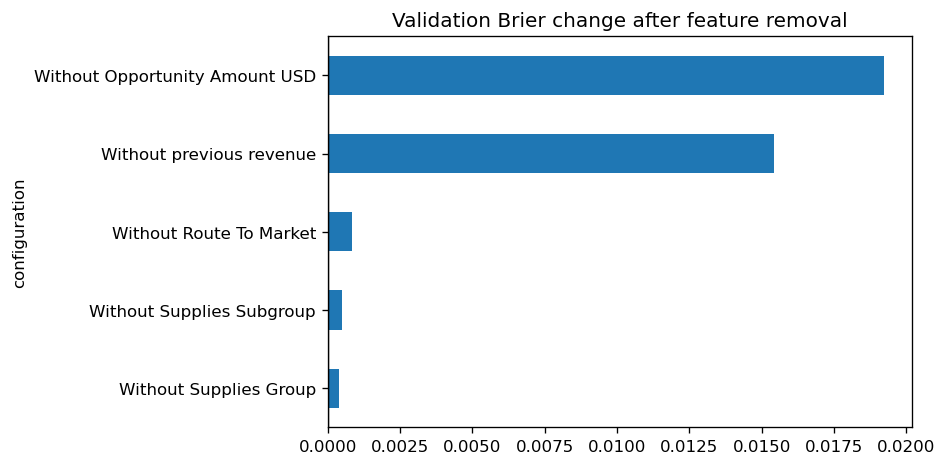

In [8]:
def ablation_preprocessor(columns):
    parts=[]; categorical=[c for c in columns if c!=AMOUNT]
    if categorical: parts.append(('categorical',OneHotEncoder(handle_unknown='ignore',sparse_output=False),categorical))
    if AMOUNT in columns: parts.append(('amount',Pipeline([('log1p',FunctionTransformer(np.log1p,feature_names_out='one-to-one')),('scale',StandardScaler())]),[AMOUNT]))
    return ColumnTransformer(parts)
def ablation_model(columns): return Pipeline([('preprocess',ablation_preprocessor(columns)),('model',RandomForestClassifier(n_estimators=200,max_depth=12,min_samples_leaf=30,max_features=.8,n_jobs=2,random_state=RANDOM_SEED))])
rows=[{'configuration':'Automotive 5 baseline',**baseline_metrics,'training seconds':0.0}]
fallback=joblib.load(root/'models/automotive_v1/automotive_limited_history_fallback.joblib'); fallback_columns=[AMOUNT,'Route To Market','Supplies Group','Supplies Subgroup']
t=perf_counter(); rows.append({'configuration':'Without previous revenue',**metrics(validation.target,fallback.predict_proba(validation[fallback_columns])[:,1]),'training seconds':perf_counter()-t})
for removed in [AMOUNT,'Route To Market','Supplies Group','Supplies Subgroup']:
    columns=[c for c in FEATURES if c!=removed]; t=perf_counter(); model=ablation_model(columns).fit(train[columns],train.target); probabilities=model.predict_proba(validation[columns])[:,1]
    rows.append({'configuration':f'Without {removed}',**metrics(validation.target,probabilities),'training seconds':perf_counter()-t})
ablation=pd.DataFrame(rows)
for metric in frozen_metrics: ablation[f'{metric} change']=ablation[metric]-baseline_metrics[metric]
display(ablation.round(5)); print(f'New ablation fitting: {ablation["training seconds"].sum():.2f}s; revenue removal reused the fallback artifact.')
ax=ablation.set_index('configuration')['Brier Score change'].drop('Automotive 5 baseline').sort_values().plot.barh(figsize=(8,4),title='Validation Brier change after feature removal'); ax.axvline(0,color='black',linewidth=.8); plt.tight_layout(); plt.show()


In [9]:
class RelativeSubgroupAmount(BaseEstimator,TransformerMixin):
    column='Relative log amount to subgroup median'
    def fit(self,X,y=None):
        logged=X.assign(_log=np.log1p(X[AMOUNT])); self.medians_=logged.groupby('Supplies Subgroup')['_log'].median(); self.fallback_=logged['_log'].median(); return self
    def transform(self,X):
        result=X.copy(); reference=result['Supplies Subgroup'].map(self.medians_).fillna(self.fallback_); result[self.column]=np.log1p(result[AMOUNT])-reference; return result
RELATIVE_AMOUNT=RelativeSubgroupAmount.column
relative_preprocessor=ColumnTransformer([('categorical',OneHotEncoder(handle_unknown='ignore',sparse_output=False),FEATURES[1:]),('amount',Pipeline([('log1p',FunctionTransformer(np.log1p,feature_names_out='one-to-one')),('scale',StandardScaler())]),[AMOUNT]),('relative',StandardScaler(),[RELATIVE_AMOUNT])])
relative_model=Pipeline([('feature_engineering',RelativeSubgroupAmount()),('preprocess',relative_preprocessor),('model',RandomForestClassifier(n_estimators=200,max_depth=12,min_samples_leaf=30,max_features=.8,n_jobs=2,random_state=RANDOM_SEED))])
t=perf_counter(); relative_model.fit(train[FEATURES],train.target); relative_seconds=perf_counter()-t; relative_metrics=metrics(validation.target,relative_model.predict_proba(validation[FEATURES])[:,1])
performance=pd.DataFrame([{'model':'Frozen Automotive 5',**baseline_metrics},{'model':'FE1 subgroup × route','ROC-AUC':.8209877888209578,'Average Precision':.6082295950523401,'Brier Score':.12909867503677047},{'model':'FE2 relative subgroup amount',**relative_metrics}])
for metric in frozen_metrics: performance[f'{metric} change']=performance[metric]-baseline_metrics[metric]
display(performance.round(5)); print(f'FE2 fitting: {relative_seconds:.2f}s; medians fitted on training only.')


                          model  ROC-AUC  Average Precision  Brier Score  ROC-AUC change  Average Precision change  Brier Score change
0           Frozen Automotive 5  0.82083            0.60763      0.12921         0.00000                   0.00000             0.00000
1          FE1 subgroup × route  0.82099            0.60823      0.12910         0.00015                   0.00060            -0.00011
2  FE2 relative subgroup amount  0.82249            0.60795      0.12874         0.00166                   0.00033            -0.00046
FE2 fitting: 9.01s; medians fitted on training only.


                                        Baseline mean abs SHAP  FE2 mean abs SHAP   Change  Baseline attribution share  FE2 attribution share
Opportunity Amount USD                                 0.10137            0.09267 -0.00870                     0.42673                0.38417
Revenue From Client Past Two Years                     0.09334            0.09231 -0.00103                     0.39294                0.38269
Route To Market                                        0.03170            0.02696 -0.00473                     0.13344                0.11178
Supplies Group                                         0.00329            0.00349  0.00021                     0.01383                0.01448
Supplies Subgroup                                      0.00785            0.00417 -0.00368                     0.03306                0.01729
Relative log amount to subgroup median                 0.00000            0.02161  0.02161                     0.00000                0.08958
      

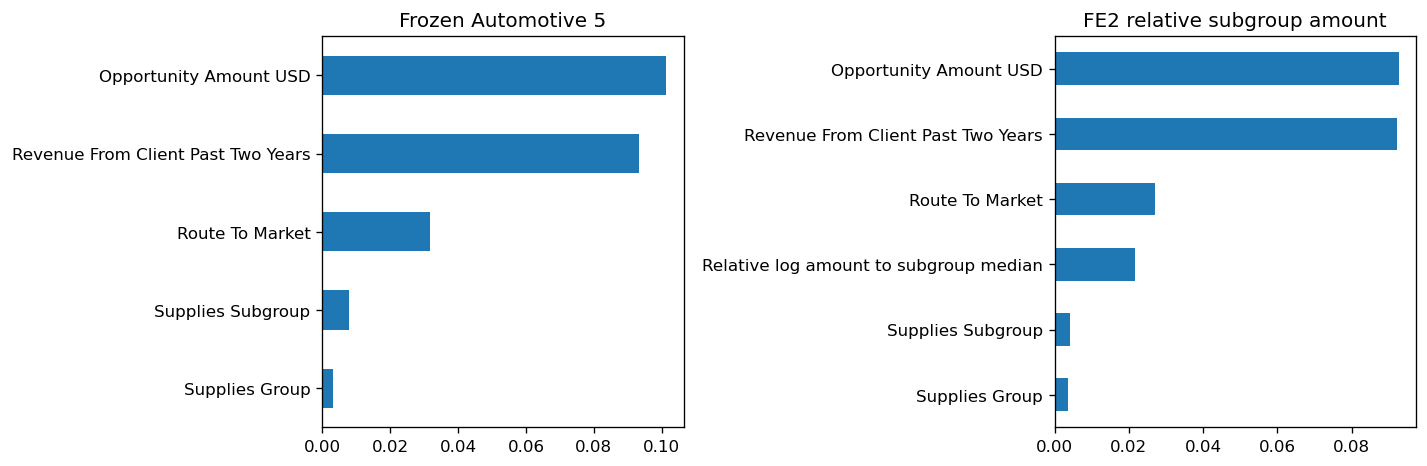

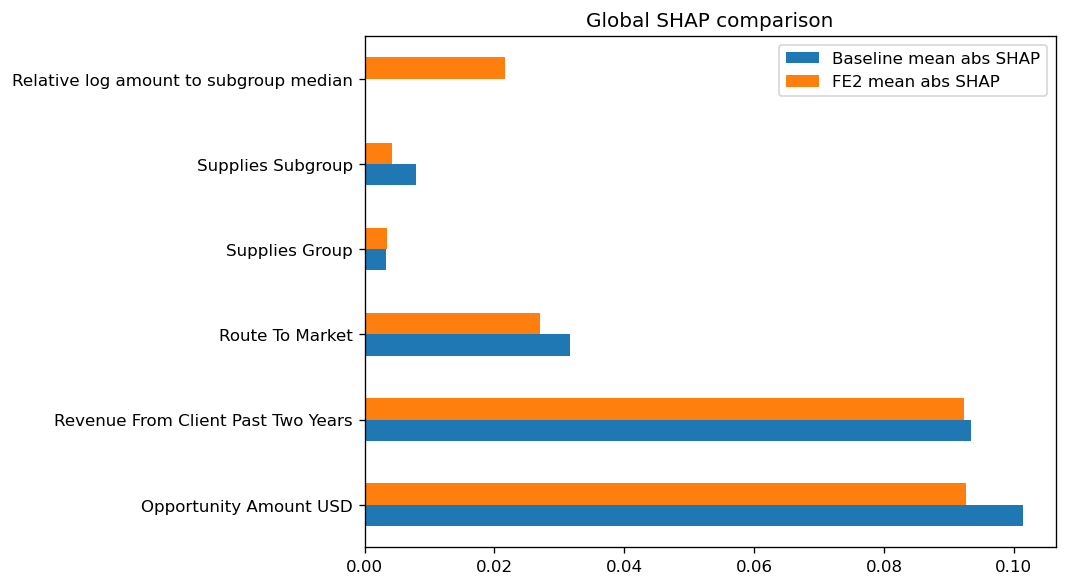

In [10]:
relative_shap,relative_shap_seconds=business_shap(relative_model,shap_sample,shap_background,FEATURES,RELATIVE_AMOUNT)
base=baseline_shap.abs().mean().rename('Baseline mean abs SHAP'); engineered=relative_shap.abs().mean().rename('FE2 mean abs SHAP')
shap_refinement=pd.concat([base,engineered],axis=1).fillna(0); shap_refinement['Change']=shap_refinement['FE2 mean abs SHAP']-shap_refinement['Baseline mean abs SHAP']; shap_refinement['Baseline attribution share']=shap_refinement['Baseline mean abs SHAP']/shap_refinement['Baseline mean abs SHAP'].sum(); shap_refinement['FE2 attribution share']=shap_refinement['FE2 mean abs SHAP']/shap_refinement['FE2 mean abs SHAP'].sum()
display(shap_refinement.round(5))
hierarchy=pd.DataFrame({'mean abs grouped contribution':[(baseline_shap['Supplies Group']+baseline_shap['Supplies Subgroup']).abs().mean(),(relative_shap['Supplies Group']+relative_shap['Supplies Subgroup']).abs().mean()]},index=['Baseline','FE2']); display(hierarchy.round(5)); print(f'FE2 SHAP: {relative_shap_seconds:.2f}s; additivity verified on the same 100/50 sample.')
fig,axes=plt.subplots(1,2,figsize=(12,4)); base.sort_values().plot.barh(ax=axes[0],title='Frozen Automotive 5'); engineered.sort_values().plot.barh(ax=axes[1],title='FE2 relative subgroup amount'); plt.tight_layout(); plt.show()
shap_refinement[['Baseline mean abs SHAP','FE2 mean abs SHAP']].plot.barh(figsize=(9,5),title='Global SHAP comparison'); plt.tight_layout(); plt.show()


## Final Model Selection and Interpretation

The investigation proceeded from the candidate-feature and model comparison in Notebook 08 to selection and frozen evaluation of Automotive v1, followed by estimator-count checks, feature ablation, two targeted product-aware features, and like-for-like SHAP comparisons. A separate Colab run then compared the same Random Forest experiments with one tested TensorFlow configuration. The production decision remains **Automotive v1 — Five-Feature Random Forest**: Opportunity Amount USD, Revenue From Client Past Two Years, Route To Market, Supplies Group and Supplies Subgroup. Its frozen Notebook 08 test ROC-AUC/AP/Brier/F1 are **0.81441 / 0.60221 / 0.13079 / 0.57642**; these test results were not recomputed here.

Ablation used validation data only. Removing amount caused the largest deterioration (ROC-AUC/AP/Brier **0.71465 / 0.48439 / 0.14843**), followed by removing previous revenue (**0.77858 / 0.49058 / 0.14464**). Removing route produced **0.81509 / 0.60194 / 0.13005**, a smaller but measurable deterioration. Removing group or subgroup individually caused little change because each observed subgroup maps to one group in this extract, so the hierarchy overlaps statistically. This does not show that product categories lack business relevance.

FE1 subgroup × route reached validation ROC-AUC/AP/Brier **0.82099 / 0.60823 / 0.12910**. FE2 training-only subgroup-relative log amount gave the strongest engineered validation result, **0.82249 / 0.60795 / 0.12874**, changing the frozen baseline by approximately **+0.00166 / +0.00033 / -0.00047** (rounding explains the displayed Brier change of -0.00046). Its added SHAP attribution mainly redistributed opportunity-amount information; it did not meaningfully strengthen Route To Market or the combined raw group/subgroup hierarchy. The validation gain is too small to justify a new artifact, inference contract and deployment evaluation, so the established model is retained.

The TensorFlow figures were produced in a separate Colab run of `notebooks/regression_pipeline.py`, not in Notebook 10. That supplied run reported validation ROC-AUC/AP/Brier/F1 of **0.76622 / 0.55196 / 0.14008 / 0.51346**, versus **0.82083 / 0.60763 / 0.12921 / 0.58065** for the original RF and **0.82099 / 0.60823 / 0.12910 / 0.57866** for FE1. The repository's current `notebooks/results/regression_pipeline/results.json` records TensorFlow as skipped locally because it was not installed; therefore the Colab result is external evidence for this tested configuration, not a Notebook 10 output and not evidence that every neural-network architecture is inferior.

SHAP values here are feature attributions for learned associations. Their normalized attribution shares are not percentages of predicted probability, and neither SHAP nor ablation establishes economic, political or other causal effects. The IBM automotive/RV subset is public evaluation data rather than verified operational data from a future adopting organization; some categories overlap, sparse combinations remain, and validation gains do not establish improvement on unseen populations. Reliable historical revenue is essential: unknown or incomplete history must not be represented as verified zero. Human prediction reviews are also not authoritative Won/Lost labels.

## Future organizational model refinement

The application currently implements versioned prediction history, input snapshots and separate human prediction reviews. Those reviews must remain distinct from authoritative verified Won/Lost outcomes. Future data collection should retain prediction-time snapshots of the original inputs, reliable client revenue history, and only interaction or follow-up records available before prediction. Planned monitoring should cover business impact, probability calibration and subgroup performance. Future retraining has not been implemented or validated: any candidate must undergo versioned evaluation before deployment, and no claim is made that operational AutoBridge data has already improved model performance.

**Decision:** retain the frozen Automotive v1 artifact, metadata, preprocessing, raw Won-probability calculation and five-feature contract unchanged.